<a href="https://colab.research.google.com/github/Asmae215/Photo/blob/main/TP_GAN_espace_latent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn import datasets
import torchvision, torchvision.transforms as T

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
torch.manual_seed(0); np.random.seed(0)

Device : cuda


# TP 1 – Generative Adversarial Networks
## 1.2 Jeu de données jouet : points sur un cercle

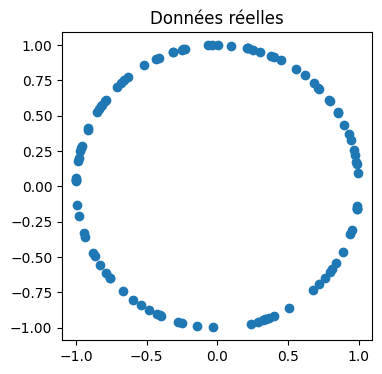

In [2]:
X = np.random.randn(100, 2)
X /= np.linalg.norm(X, axis=1)[:, None].repeat(2, axis=1)

data_dim = X.shape[-1]
hidden_dim = 10

plt.figure(figsize=(4, 4)); plt.scatter(X[:, 0], X[:, 1]); plt.axis("equal"); plt.title("Données réelles"); plt.show()

### Question 1 – Architectures de G et D

In [3]:
def make_G(hidden_dim, data_dim, width=64):
    # Générateur entièrement connecté à 3 couches : z (hidden_dim) -> x (data_dim)
    return nn.Sequential(
        nn.Linear(hidden_dim, width), nn.ReLU(),
        nn.Linear(width, width), nn.ReLU(),
        nn.Linear(width, data_dim),
    )

def make_D(data_dim, width=64):
    # Discriminateur : x (data_dim) -> probabilité d'être réel (sigmoïde)
    return nn.Sequential(
        nn.Linear(data_dim, width), nn.LeakyReLU(0.2),
        nn.Linear(width, width), nn.LeakyReLU(0.2),
        nn.Linear(width, 1), nn.Sigmoid(),
    )

G = make_G(hidden_dim, data_dim); D = make_D(data_dim)
print(G); print(D)

Sequential(
  (0): Linear(in_features=10, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=2, bias=True)
)
Sequential(
  (0): Linear(in_features=2, out_features=64, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): LeakyReLU(negative_slope=0.2)
  (4): Linear(in_features=64, out_features=1, bias=True)
  (5): Sigmoid()
)


### Question 2 – Boucle d'apprentissage

- **D** minimise `BCE(D(x),1) + BCE(D(G(z).detach()),0)`, ce qui revient à maximiser `log D(x) + log(1 - D(x̂))` ;
- **G** minimise `BCE(D(G(z)),1)` (version *non saturante* de `log(1 - D(G(z)))`, qui donne de meilleurs gradients en début d'apprentissage ; elle pousse aussi D à prédire « réel » sur les données synthétiques).

iter   500 | loss D = 1.420 | loss G = 0.716
iter  1000 | loss D = 1.322 | loss G = 0.736
iter  1500 | loss D = 1.382 | loss G = 0.722
iter  2000 | loss D = 1.377 | loss G = 0.715
iter  2500 | loss D = 1.377 | loss G = 0.696
iter  3000 | loss D = 1.377 | loss G = 0.696


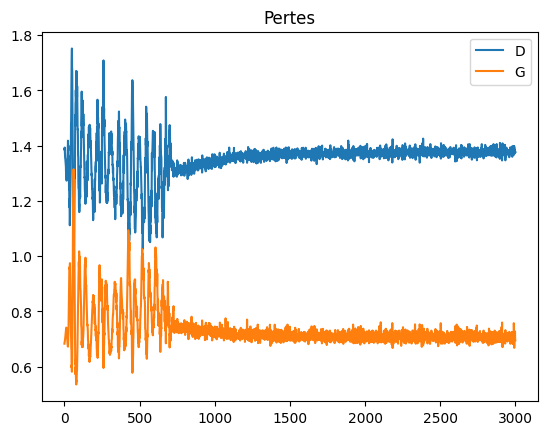

In [4]:
def train_gan(X, hidden_dim, n_iter=3000, batch_size=64, lr=1e-3, width=64, verbose=True):
    X_t = torch.tensor(X, dtype=torch.float32, device=device)
    data_dim = X_t.shape[1]
    G = make_G(hidden_dim, data_dim, width).to(device)
    D = make_D(data_dim, width).to(device)
    opt_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    bce = nn.BCELoss()
    ones = torch.ones(batch_size, 1, device=device)
    zeros = torch.zeros(batch_size, 1, device=device)
    hist = {"D": [], "G": []}

    for it in range(n_iter):
        # 1. batch de données réelles
        x = X_t[torch.randint(0, len(X_t), (batch_size,), device=device)]
        # 2. bruit aléatoire z ~ N(0,1)
        z = torch.randn(batch_size, hidden_dim, device=device)
        # 3. fausses données
        x_fake = G(z)
        # 4-5. coût et pas d'optimisation de D (detach : pas de gradient dans G)
        loss_D = bce(D(x), ones) + bce(D(x_fake.detach()), zeros)
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()
        # 6-7. coût et pas d'optimisation de G
        loss_G = bce(D(x_fake), ones)
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()

        hist["D"].append(loss_D.item()); hist["G"].append(loss_G.item())
        if verbose and (it + 1) % 500 == 0:
            print(f"iter {it+1:5d} | loss D = {loss_D.item():.3f} | loss G = {loss_G.item():.3f}")
    return G, D, hist

G, D, hist = train_gan(X, hidden_dim)
plt.plot(hist["D"], label="D"); plt.plot(hist["G"], label="G"); plt.legend(); plt.title("Pertes"); plt.show()

### Question 3 – Visualisation des points générés

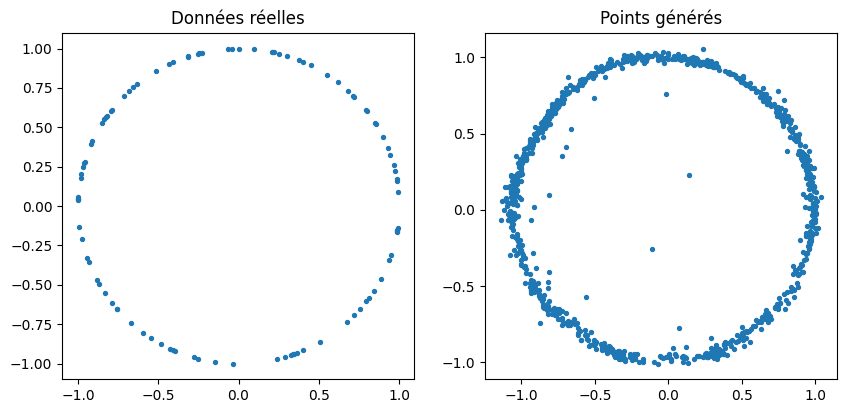

In [5]:
def generate(G, n, hidden_dim):
    G.eval()
    with torch.no_grad():
        z = torch.randn(n, hidden_dim, device=device)
        return G(z)

def scatter(ax, P, c=None, title=""):
    if P.shape[1] == 3:
        ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=c, s=5)
    else:
        ax.scatter(P[:, 0], P[:, 1], c=c, s=8)
    ax.set_title(title)

def plot_real_fake(X, X_fake, colors=None, title_fake="Points générés"):
    dim = X.shape[1]
    kw = {"projection": "3d"} if dim == 3 else {}
    fig = plt.figure(figsize=(10, 4.5))
    ax1 = fig.add_subplot(1, 2, 1, **kw); scatter(ax1, X, None, "Données réelles")
    ax2 = fig.add_subplot(1, 2, 2, **kw); scatter(ax2, X_fake, colors, title_fake)
    plt.show()

X_fake = generate(G, 1000, hidden_dim).cpu().numpy()
plot_real_fake(X, X_fake)

### Question 4 – Décision du discriminateur (seuil 0.5)

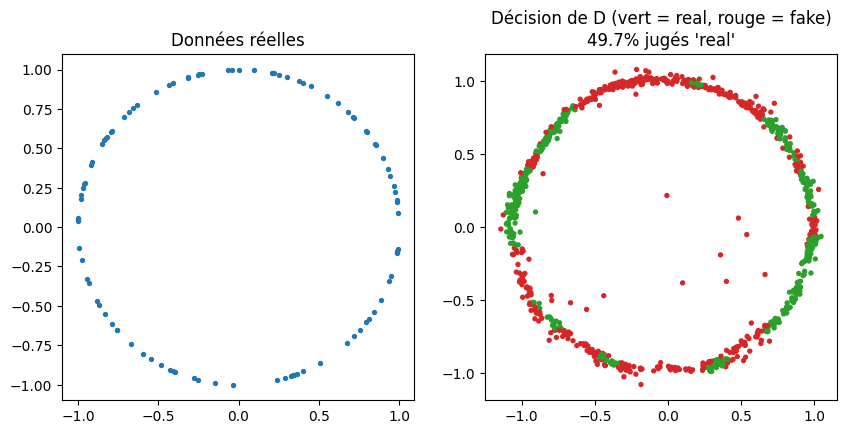

In [6]:
def plot_decision(G, D, X, hidden_dim, n=1000):
    Xf = generate(G, n, hidden_dim)
    D.eval()
    with torch.no_grad():
        p = D(Xf).squeeze(1).cpu().numpy()
    Xf = Xf.cpu().numpy()
    is_real = p > 0.5
    colors = np.where(is_real, "tab:green", "tab:red")
    plot_real_fake(X, Xf, colors, f"Décision de D (vert = real, rouge = fake)\n{is_real.mean()*100:.1f}% jugés 'real'")

plot_decision(G, D, X, hidden_dim)

## 1.3 Demi-lunes (optionnel – Question 5)

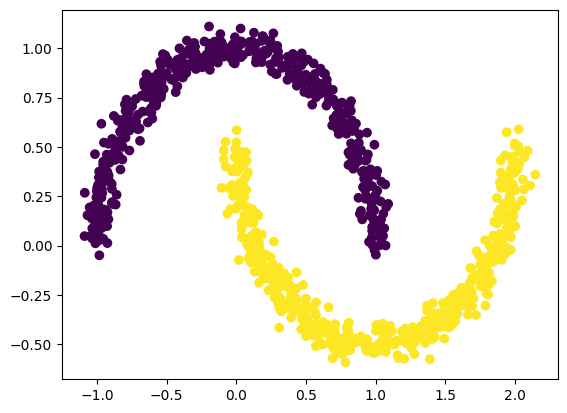

iter   500 | loss D = 1.345 | loss G = 0.657
iter  1000 | loss D = 1.471 | loss G = 0.702
iter  1500 | loss D = 1.307 | loss G = 0.729
iter  2000 | loss D = 1.370 | loss G = 0.729
iter  2500 | loss D = 1.379 | loss G = 0.692
iter  3000 | loss D = 1.379 | loss G = 0.676
iter  3500 | loss D = 1.384 | loss G = 0.711
iter  4000 | loss D = 1.376 | loss G = 0.694
iter  4500 | loss D = 1.386 | loss G = 0.681
iter  5000 | loss D = 1.412 | loss G = 0.681


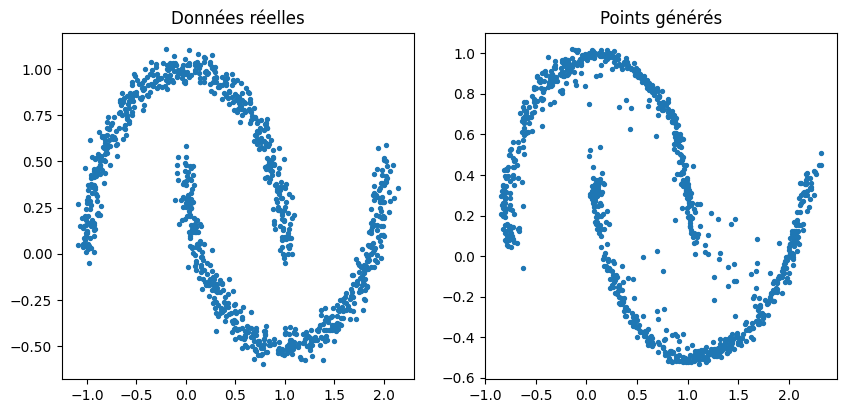

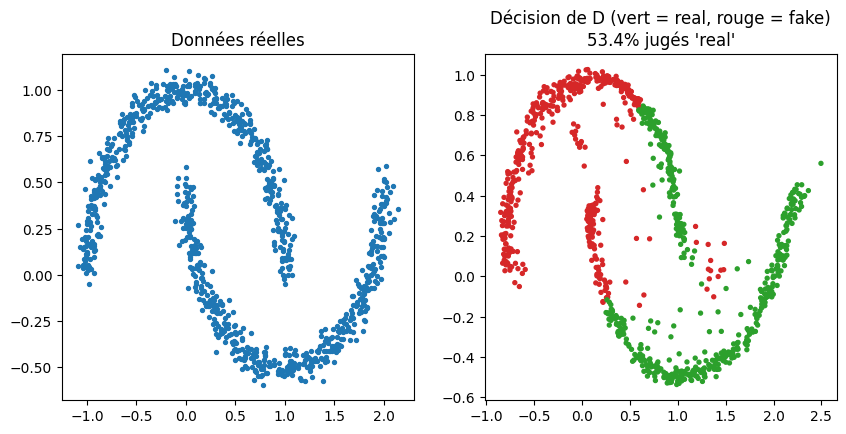

In [7]:
Xm, ym = datasets.make_moons(n_samples=1000, noise=0.05)
plt.scatter(Xm[:, 0], Xm[:, 1], c=ym); plt.show()

Gm, Dm, hm = train_gan(Xm, hidden_dim=10, n_iter=5000)
plot_real_fake(Xm, generate(Gm, 1000, 10).cpu().numpy())
plot_decision(Gm, Dm, Xm, 10)

## 1.4 Swiss roll (optionnel – Question 6)
On répète l'expérience en faisant varier la dimension de l'espace latent.

=== Dimension de l'espace latent : 1 ===


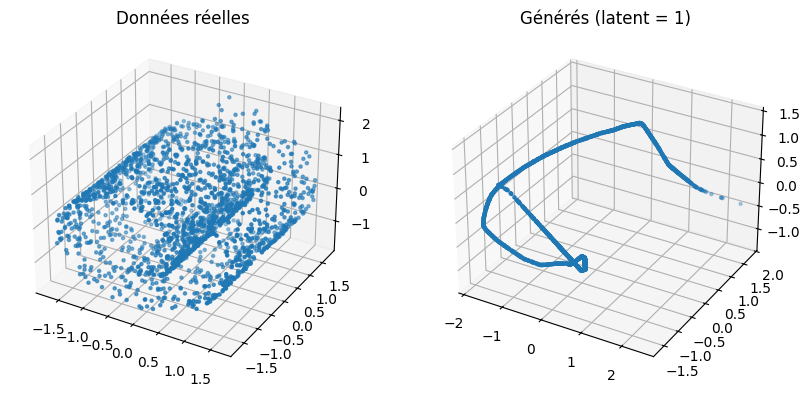

=== Dimension de l'espace latent : 2 ===


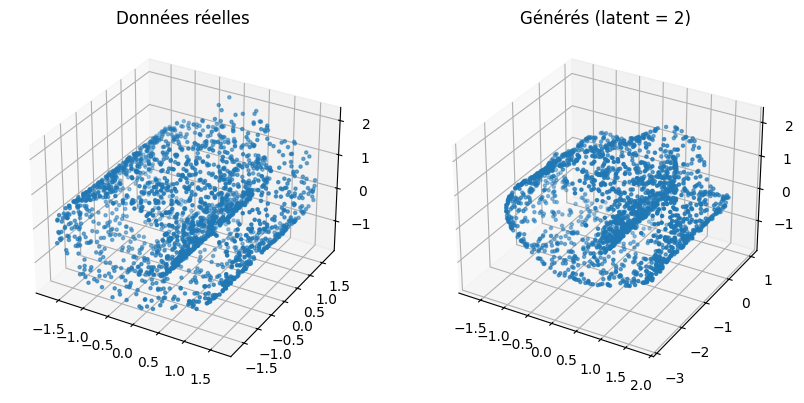

=== Dimension de l'espace latent : 3 ===


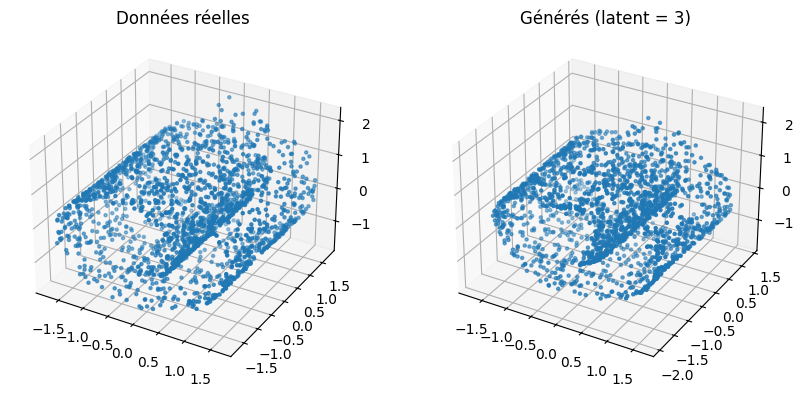

=== Dimension de l'espace latent : 10 ===


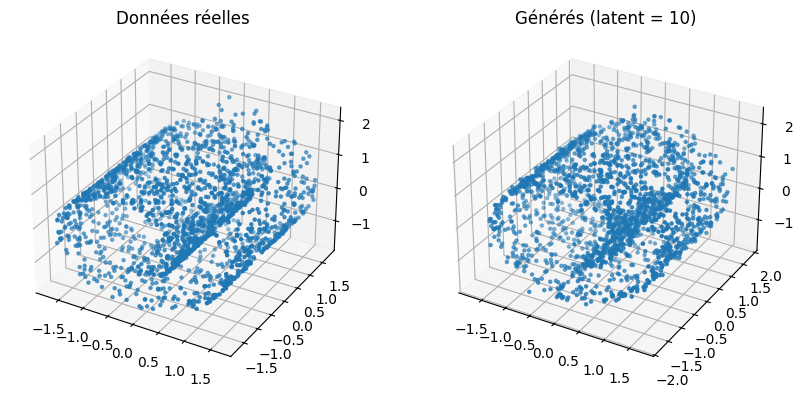

In [8]:
Xs, ys = datasets.make_swiss_roll(n_samples=2000, noise=0.05)
Xs = (Xs - Xs.mean(0)) / Xs.std(0)   # normalisation pour faciliter l'apprentissage

for hd in [1, 2, 3, 10]:
    print(f"=== Dimension de l'espace latent : {hd} ===")
    Gs, Ds, hs = train_gan(Xs, hidden_dim=hd, n_iter=6000, width=128, verbose=False)
    plot_real_fake(Xs, generate(Gs, 2000, hd).cpu().numpy(), title_fake=f"Générés (latent = {hd})")

**Observation attendue** : le Swiss roll est une variété de dimension intrinsèque 2 plongée dans ℝ³. Avec un espace latent de dimension 1, le générateur ne peut produire qu'une **courbe** (image d'une droite) : il ne couvre pas toute la surface. À partir de la dimension 2, il peut en principe couvrir toute la nappe ; au-delà, les dimensions supplémentaires sont redondantes.

## 1.5 GAN conditionnel sur MNIST
### Question 7 – cGAN (MLP, conditionnement one-hot)

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 498kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.68MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.72MB/s]


epoch   1/20 | loss D = 1.025 | loss G = 1.415
epoch   2/20 | loss D = 0.883 | loss G = 1.591
epoch   3/20 | loss D = 0.842 | loss G = 1.814
epoch   4/20 | loss D = 0.618 | loss G = 2.693
epoch   5/20 | loss D = 0.674 | loss G = 2.660
epoch   6/20 | loss D = 0.661 | loss G = 2.253
epoch   7/20 | loss D = 0.777 | loss G = 1.774
epoch   8/20 | loss D = 0.847 | loss G = 1.273
epoch   9/20 | loss D = 0.966 | loss G = 1.228
epoch  10/20 | loss D = 0.988 | loss G = 1.307
epoch  11/20 | loss D = 1.085 | loss G = 1.488
epoch  12/20 | loss D = 1.118 | loss G = 1.293
epoch  13/20 | loss D = 1.211 | loss G = 0.752
epoch  14/20 | loss D = 1.230 | loss G = 0.778
epoch  15/20 | loss D = 1.120 | loss G = 0.980
epoch  16/20 | loss D = 1.236 | loss G = 1.061
epoch  17/20 | loss D = 1.199 | loss G = 0.961
epoch  18/20 | loss D = 1.219 | loss G = 0.863
epoch  19/20 | loss D = 1.223 | loss G = 0.947
epoch  20/20 | loss D = 1.249 | loss G = 0.777


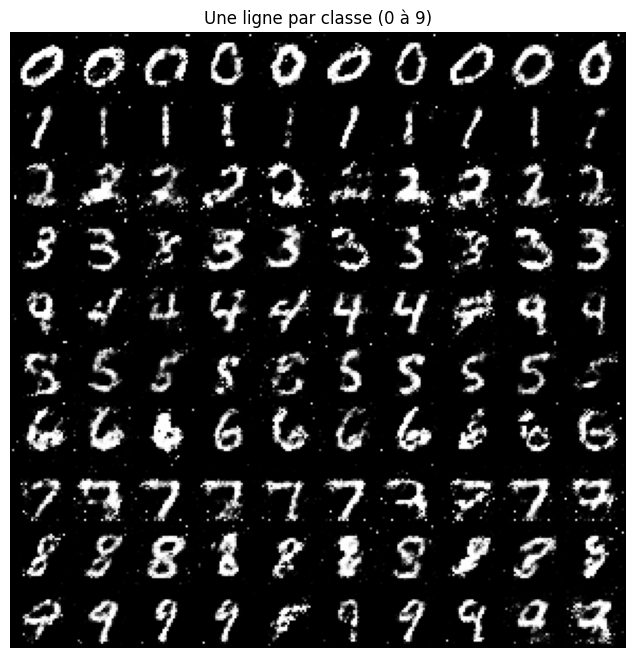

In [9]:
transform = T.Compose([T.ToTensor(), T.Normalize((0.5,), (0.5,))])   # images dans [-1, 1]
mnist_train = torchvision.datasets.MNIST("./data", train=True, download=True, transform=transform)
mnist_test = torchvision.datasets.MNIST("./data", train=False, download=True, transform=transform)
loader = DataLoader(mnist_train, batch_size=128, shuffle=True, drop_last=True, num_workers=2)

Z_DIM, N_CLASSES = 100, 10

class CondG_MLP(nn.Module):
    def __init__(self, z_dim=Z_DIM, n_classes=N_CLASSES):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim + n_classes, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2),
            nn.Linear(1024, 784), nn.Tanh())
    def forward(self, z, y):
        return self.net(torch.cat([z, y], 1)).view(-1, 1, 28, 28)

class CondD_MLP(nn.Module):
    def __init__(self, n_classes=N_CLASSES):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784 + n_classes, 512), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(256, 1), nn.Sigmoid())
    def forward(self, x, y):
        return self.net(torch.cat([x.view(x.size(0), -1), y], 1))

def train_cgan(G, D, epochs=20, lr=2e-4):
    G.to(device); D.to(device)
    opt_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    bce = nn.BCELoss()
    for ep in range(epochs):
        G.train(); D.train()
        for x, lab in loader:
            x, lab = x.to(device), lab.to(device)
            B = x.size(0)
            y = F.one_hot(lab, N_CLASSES).float()
            ones, zeros = torch.ones(B, 1, device=device), torch.zeros(B, 1, device=device)
            z = torch.randn(B, Z_DIM, device=device)
            x_fake = G(z, y)
            loss_D = bce(D(x, y), ones) + bce(D(x_fake.detach(), y), zeros)
            opt_D.zero_grad(); loss_D.backward(); opt_D.step()
            loss_G = bce(D(x_fake, y), ones)
            opt_G.zero_grad(); loss_G.backward(); opt_G.step()
        print(f"epoch {ep+1:3d}/{epochs} | loss D = {loss_D.item():.3f} | loss G = {loss_G.item():.3f}")
    return G, D

def show_conditional(G, n_per_class=10):
    G.eval()
    with torch.no_grad():
        labels = torch.arange(10, device=device).repeat_interleave(n_per_class)
        y = F.one_hot(labels, N_CLASSES).float()
        z = torch.randn(len(labels), Z_DIM, device=device)
        imgs = G(z, y).cpu()
    grid = torchvision.utils.make_grid(imgs, nrow=n_per_class, normalize=True, value_range=(-1, 1), padding=1)
    plt.figure(figsize=(8, 8)); plt.imshow(grid.permute(1, 2, 0)); plt.axis("off")
    plt.title("Une ligne par classe (0 à 9)"); plt.show()

G_mlp, D_mlp = train_cgan(CondG_MLP(), CondD_MLP(), epochs=20)
show_conditional(G_mlp)

### Question 8 – Modèles convolutifs (optionnel)

epoch   1/10 | loss D = 0.950 | loss G = 2.138
epoch   2/10 | loss D = 0.381 | loss G = 1.872
epoch   3/10 | loss D = 0.258 | loss G = 2.292
epoch   4/10 | loss D = 0.355 | loss G = 1.880
epoch   5/10 | loss D = 0.445 | loss G = 1.860
epoch   6/10 | loss D = 0.456 | loss G = 1.375
epoch   7/10 | loss D = 0.601 | loss G = 1.260
epoch   8/10 | loss D = 0.842 | loss G = 1.525
epoch   9/10 | loss D = 0.627 | loss G = 2.009
epoch  10/10 | loss D = 0.491 | loss G = 1.998


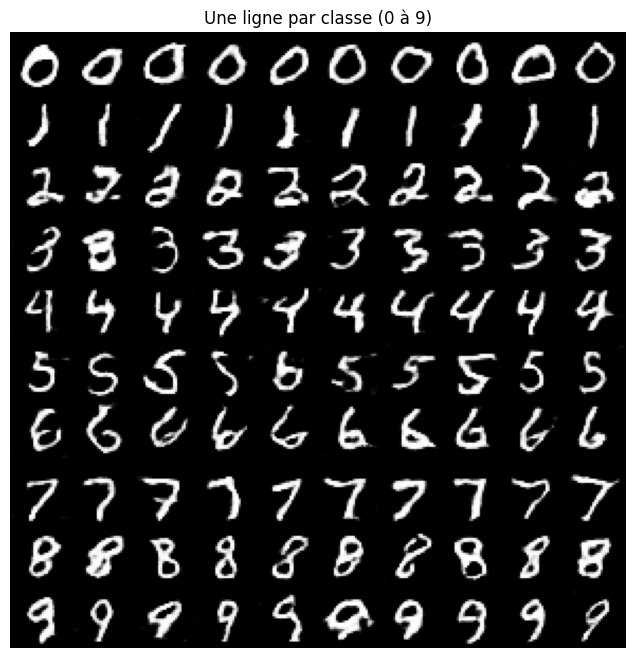

In [10]:
class CondG_Conv(nn.Module):
    def __init__(self, z_dim=Z_DIM, n_classes=N_CLASSES):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(z_dim + n_classes, 128 * 7 * 7), nn.BatchNorm1d(128 * 7 * 7), nn.ReLU())
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),   # 7 -> 14
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())                          # 14 -> 28
    def forward(self, z, y):
        h = self.fc(torch.cat([z, y], 1)).view(-1, 128, 7, 7)
        return self.deconv(h)

class CondD_Conv(nn.Module):
    def __init__(self, n_classes=N_CLASSES):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1 + n_classes, 64, 4, 2, 1), nn.LeakyReLU(0.2),                    # 28 -> 14
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2))         # 14 -> 7
        self.fc = nn.Sequential(nn.Flatten(), nn.Linear(128 * 7 * 7, 1), nn.Sigmoid())
    def forward(self, x, y):
        y_maps = y.view(y.size(0), -1, 1, 1).expand(-1, -1, x.size(2), x.size(3))   # one-hot -> cartes
        return self.fc(self.conv(torch.cat([x, y_maps], 1)))

G_conv, D_conv = train_cgan(CondG_Conv(), CondD_Conv(), epochs=10)
show_conditional(G_conv)

# TP 2 – Espace latent des GAN
## 2.1 Préparation : DCGAN et LeNet5
L'énoncé suppose un DCGAN (espace latent de dimension 100, codes ~ N(0,1)) et un LeNet5 préentraînés. Ici on les entraîne rapidement.

In [11]:
NZ = 100

class DCGenerator(nn.Module):
    def __init__(self, nz=NZ):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, 256, 7, 1, 0, bias=False), nn.BatchNorm2d(256), nn.ReLU(True),   # 1 -> 7
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),  # 7 -> 14
            nn.ConvTranspose2d(128, 1, 4, 2, 1), nn.Tanh())                                         # 14 -> 28
    def forward(self, z):
        return self.net(z)

class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),
            nn.Conv2d(128, 1, 7, 1, 0), nn.Sigmoid())
    def forward(self, x):
        return self.net(x).view(-1, 1)

def train_dcgan(epochs=15, lr=2e-4):
    G, D = DCGenerator().to(device), DCDiscriminator().to(device)
    opt_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    bce = nn.BCELoss()
    for ep in range(epochs):
        for x, _ in loader:
            x = x.to(device); B = x.size(0)
            ones, zeros = torch.ones(B, 1, device=device), torch.zeros(B, 1, device=device)
            z = torch.randn(B, NZ, 1, 1, device=device)
            x_fake = G(z)
            loss_D = bce(D(x), ones) + bce(D(x_fake.detach()), zeros)
            opt_D.zero_grad(); loss_D.backward(); opt_D.step()
            loss_G = bce(D(x_fake), ones)
            opt_G.zero_grad(); loss_G.backward(); opt_G.step()
        print(f"epoch {ep+1:3d}/{epochs} | loss D = {loss_D.item():.3f} | loss G = {loss_G.item():.3f}")
    return G

class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),   # 28 -> 14
            nn.Conv2d(6, 16, 5), nn.ReLU(), nn.MaxPool2d(2))             # 14 -> 10 -> 5
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16 * 5 * 5, 120), nn.ReLU(),
            nn.Linear(120, 84), nn.ReLU(), nn.Linear(84, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

def train_lenet(epochs=3):
    net = LeNet5().to(device)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    test_loader = DataLoader(mnist_test, batch_size=1000)
    for ep in range(epochs):
        net.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(net(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        net.eval(); correct = 0
        with torch.no_grad():
            for x, y in test_loader:
                correct += (net(x.to(device)).argmax(1).cpu() == y).sum().item()
        print(f"LeNet5 epoch {ep+1} | accuracy test = {correct/len(mnist_test):.4f}")
    return net

G_dc = train_dcgan(epochs=15)
lenet = train_lenet(epochs=3)

# --- Si vous avez des poids préentraînés, décommentez et adaptez : ---
# G_dc.load_state_dict(torch.load("generator.pth", map_location=device))
# lenet.load_state_dict(torch.load("lenet5.pth", map_location=device))
G_dc.eval(); lenet.eval()

epoch   1/15 | loss D = 1.067 | loss G = 1.286
epoch   2/15 | loss D = 0.726 | loss G = 1.511
epoch   3/15 | loss D = 0.492 | loss G = 1.702
epoch   4/15 | loss D = 0.691 | loss G = 1.783
epoch   5/15 | loss D = 0.686 | loss G = 1.389
epoch   6/15 | loss D = 0.956 | loss G = 1.019
epoch   7/15 | loss D = 0.830 | loss G = 1.077
epoch   8/15 | loss D = 0.678 | loss G = 1.910
epoch   9/15 | loss D = 0.639 | loss G = 1.435
epoch  10/15 | loss D = 0.704 | loss G = 1.360
epoch  11/15 | loss D = 0.868 | loss G = 1.245
epoch  12/15 | loss D = 0.710 | loss G = 1.823
epoch  13/15 | loss D = 0.796 | loss G = 2.052
epoch  14/15 | loss D = 1.015 | loss G = 3.153
epoch  15/15 | loss D = 0.605 | loss G = 1.577
LeNet5 epoch 1 | accuracy test = 0.9721
LeNet5 epoch 2 | accuracy test = 0.9820
LeNet5 epoch 3 | accuracy test = 0.9826


LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=400, out_features=120, bias=True)
    (2): ReLU()
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): ReLU()
    (5): Linear(in_features=84, out_features=10, bias=True)
  )
)

### Question 9 – Fonction `code2image`

torch.Size([16, 28, 28])


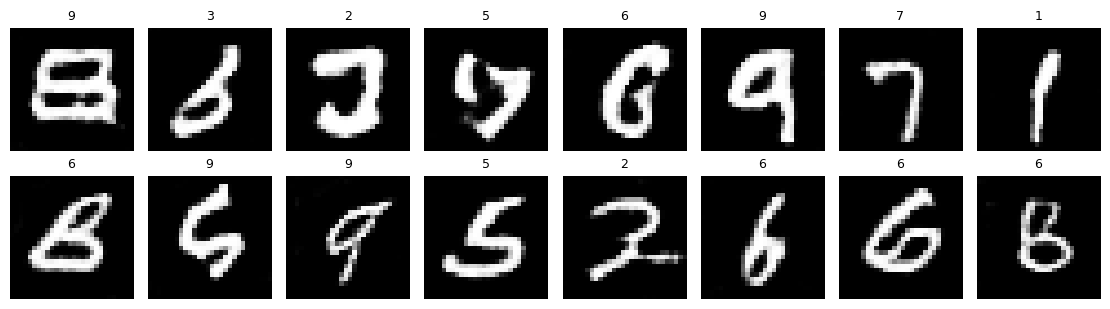

In [12]:
@torch.no_grad()
def code2image(z):
    # z : (n, 100, 1, 1) ou (n, 100) -> images (n, h, w)
    z = torch.as_tensor(z, dtype=torch.float32, device=device).reshape(-1, NZ, 1, 1)
    G_dc.eval()
    return G_dc(z).squeeze(1).cpu()

@torch.no_grad()
def classify(imgs):
    # imgs : (n, h, w) dans [-1, 1] -> classes prédites par LeNet5
    lenet.eval()
    return lenet(imgs.unsqueeze(1).to(device)).argmax(1).cpu()

def show_images(imgs, nrow=8, titles=None, figsize=None):
    n = len(imgs); ncol = min(nrow, n); nr = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nr, ncol, figsize=figsize or (1.4 * ncol, 1.6 * nr), squeeze=False)
    for i, ax in enumerate(axes.ravel()):
        ax.axis("off")
        if i < n:
            ax.imshow(imgs[i], cmap="gray", vmin=-1, vmax=1)
            if titles is not None: ax.set_title(str(titles[i]), fontsize=9)
    plt.tight_layout(); plt.show()

z = torch.randn(16, NZ)
imgs = code2image(z)
print(imgs.shape)
show_images(imgs, nrow=8, titles=classify(imgs).tolist())

## 2.2 Qualité de la distribution apprise
### Question 10 – Distribution des classes synthétiques

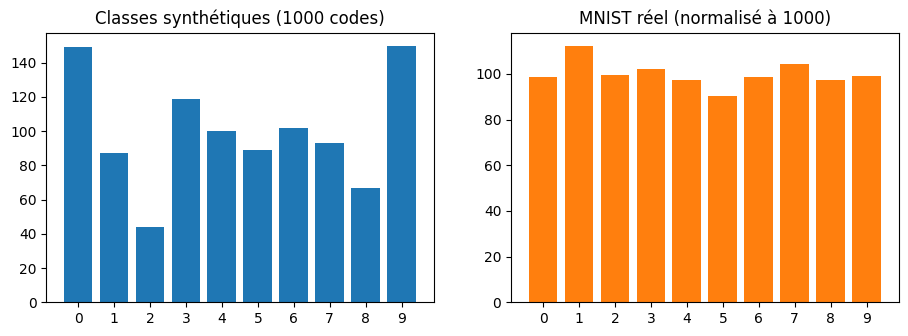

Synthétique : [149  87  44 119 100  89 102  93  67 150]


In [13]:
z = torch.randn(1000, NZ)
imgs = code2image(z)
pred = classify(imgs)
counts_syn = torch.bincount(pred, minlength=10).numpy()
counts_real = torch.bincount(mnist_train.targets, minlength=10).numpy()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(range(10), counts_syn); ax[0].set_title("Classes synthétiques (1000 codes)"); ax[0].set_xticks(range(10))
ax[1].bar(range(10), counts_real / counts_real.sum() * 1000, color="tab:orange")
ax[1].set_title("MNIST réel (normalisé à 1000)"); ax[1].set_xticks(range(10))
plt.show()
print("Synthétique :", counts_syn)

**Commentaire** : si la distribution synthétique est proche de la distribution réelle (≈ uniforme avec de légères variations), le générateur couvre bien les classes. Un déséquilibre marqué (classe sur/sous-représentée, ex. des « 1 » trop fréquents) indiquerait un début de *mode collapse* ou un biais de la distribution apprise. Comparer avec l'histogramme MNIST réel.

### Question 11 – Séparabilité des classes (SVM linéaire)

In [14]:
from sklearn.svm import LinearSVC

def flat(imgs):  # (n,28,28) -> (n,784)
    return imgs.reshape(len(imgs), -1).numpy()

# Données réelles (sous-échantillons pour la rapidité)
Xtr = ((mnist_train.data[:5000].float() / 255 - 0.5) / 0.5); ytr = mnist_train.targets[:5000].numpy()
Xte = ((mnist_test.data[:2000].float() / 255 - 0.5) / 0.5); yte = mnist_test.targets[:2000].numpy()

# 1. Données synthétiques pseudo-étiquetées par LeNet5
z_syn = torch.randn(5000, NZ)
X_syn = code2image(z_syn); y_syn = classify(X_syn).numpy()

# 2. SVM linéaire entraînée sur le réel
svm_real = LinearSVC(dual=False, C=1.0, max_iter=2000).fit(flat(Xtr), ytr)
# 3. Évaluation sur test réel
acc_real_real = svm_real.score(flat(Xte), yte)
# 4. Évaluation sur synthétique
acc_real_syn = svm_real.score(flat(X_syn), y_syn)
# 5. SVM entraînée sur synthétique, évaluée sur test réel (et sur synthétique)
svm_syn = LinearSVC(dual=False, C=1.0, max_iter=2000).fit(flat(X_syn), y_syn)
acc_syn_real = svm_syn.score(flat(Xte), yte)
acc_syn_syn = svm_syn.score(flat(X_syn), y_syn)

print(f"SVM(réel)  -> test réel        : {acc_real_real:.3f}")
print(f"SVM(réel)  -> synthétique      : {acc_real_syn:.3f}")
print(f"SVM(synth) -> test réel        : {acc_syn_real:.3f}")
print(f"SVM(synth) -> synthétique (train): {acc_syn_syn:.3f}")

SVM(réel)  -> test réel        : 0.816
SVM(réel)  -> synthétique      : 0.583
SVM(synth) -> test réel        : 0.691
SVM(synth) -> synthétique (train): 0.926


**Interprétation** :
- Si `SVM(réel) → synthétique` est proche de `SVM(réel) → test réel`, les images générées sont réalistes et leurs classes sont séparables de la même manière que les vraies.
- Un score plus élevé sur le synthétique indique des images « plus faciles » / plus prototypiques (moins de diversité) ; un score plus bas indique des images ambiguës ou éloignées de la distribution réelle.
- Si `SVM(synth) → test réel` est proche de `SVM(réel) → test réel`, les données synthétiques sont utilisables pour entraîner un classifieur (qualité + diversité suffisantes).

## 2.3 Exploration de l'espace latent
### Question 12 – Effet de la norme de z

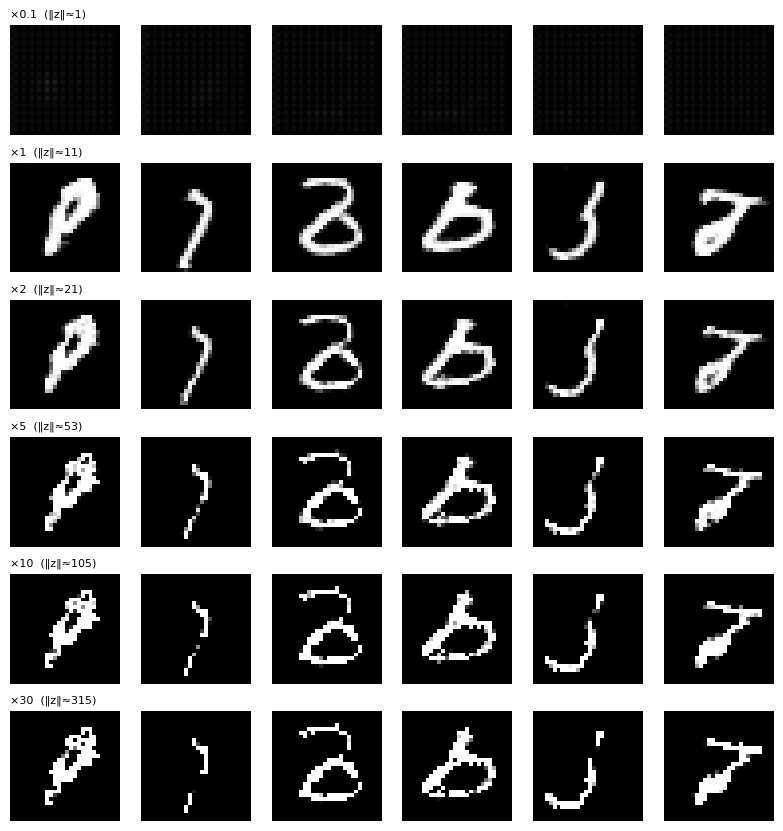

Norme typique d'un z ~ N(0, I_100) : 10.0


In [15]:
base = torch.randn(6, NZ)
scales = [0.1, 1, 2, 5, 10, 30]
fig, axes = plt.subplots(len(scales), 6, figsize=(8, 1.4 * len(scales)))
for r, s in enumerate(scales):
    zs = base * s
    imgs = code2image(zs)
    for c in range(6):
        axes[r, c].imshow(imgs[c], cmap="gray", vmin=-1, vmax=1); axes[r, c].axis("off")
    axes[r, 0].set_title(f"×{s}  (‖z‖≈{zs.norm(dim=1).mean():.0f})", fontsize=8, loc="left")
plt.tight_layout(); plt.show()
print("Norme typique d'un z ~ N(0, I_100) :", np.sqrt(NZ))

**Observation attendue** : un code tiré de N(0, I₁₀₀) a une norme ≈ √100 = 10 (la masse est concentrée sur une sphère). Quand ‖z‖ devient très grand, on sort de la zone vue à l'entraînement : les activations saturent (tanh), les images deviennent des motifs **saturés / artefacts** (noir et blanc, textures), les chiffres perdent leur forme. À l'inverse, pour ‖z‖ proche de 0 on obtient des images floues, très moyennes.

### Question 13 – Directions sémantiques entre classes

‖d_0,8‖ = 2.06


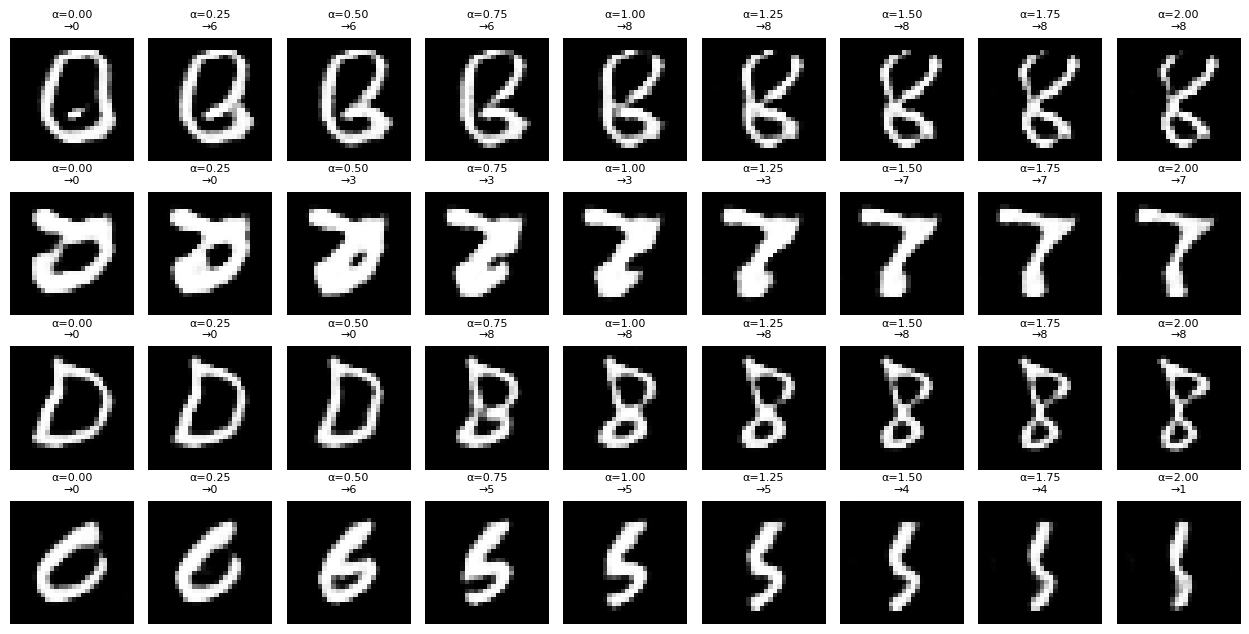

In [16]:
N = 5000
Z_all = torch.randn(N, NZ)
imgs_all = code2image(Z_all)
lab_all = classify(imgs_all)

# Barycentre de chaque classe dans l'espace latent
m = torch.stack([Z_all[lab_all == i].mean(0) for i in range(10)])

def direction(i, j):
    return m[j] - m[i]

ci, cj = 0, 8
d = direction(ci, cj)
print(f"‖d_{ci},{cj}‖ = {d.norm():.2f}")

alphas = np.linspace(0, 2, 9)
idx_start = torch.where(lab_all == ci)[0][:4]   # 4 codes de départ qui donnent un "0"

fig, axes = plt.subplots(len(idx_start), len(alphas), figsize=(1.4 * len(alphas), 1.6 * len(idx_start)))
for r, k in enumerate(idx_start):
    z0 = Z_all[k]
    imgs = code2image(torch.stack([z0 + a * d for a in alphas]))
    preds = classify(imgs)
    for c in range(len(alphas)):
        axes[r, c].imshow(imgs[c], cmap="gray", vmin=-1, vmax=1); axes[r, c].axis("off")
        axes[r, c].set_title(f"α={alphas[c]:.2f}\n→{preds[c].item()}", fontsize=8)
plt.tight_layout(); plt.show()

**Observation attendue** : en suivant la direction `d₀,₈`, le « 0 » se transforme progressivement en « 8 » (souvent en passant par des formes intermédiaires), ce qui montre que l'espace latent encode des **directions sémantiques** approximativement linéaires. Pour α trop grand, on dépasse la zone des « 8 » et l'image se dégrade. Essayez d'autres paires (`ci, cj = 1, 7` par exemple).

### Question 14 – Interpolation sphérique (slerp)

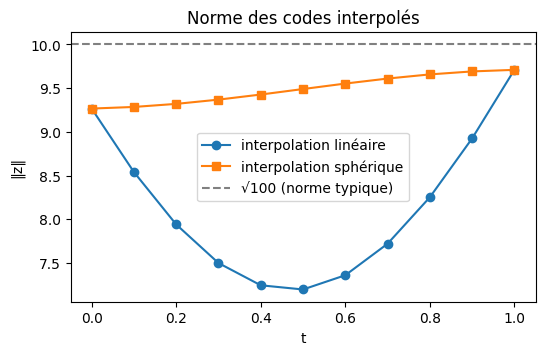

Interpolation LINÉAIRE


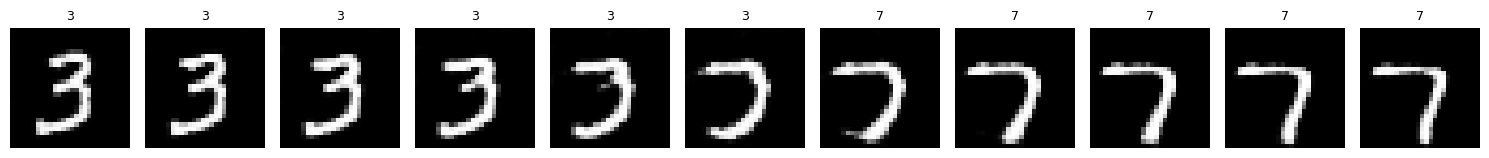

Interpolation SPHÉRIQUE


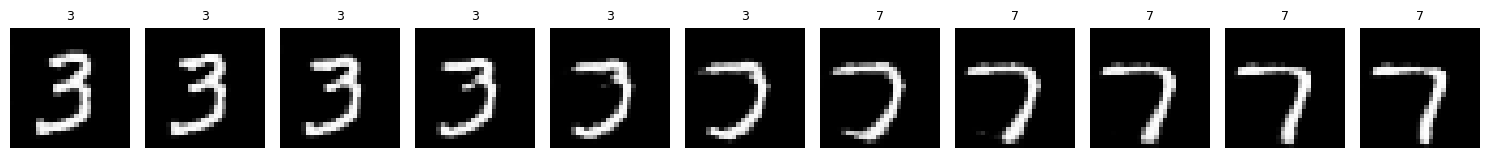

In [17]:
def lerp(z0, z1, t):
    return (1 - t) * z0 + t * z1

def slerp(z0, z1, t):
    z0n, z1n = z0 / z0.norm(), z1 / z1.norm()
    omega = torch.acos((z0n * z1n).sum().clamp(-1 + 1e-7, 1 - 1e-7))
    so = torch.sin(omega)
    return (torch.sin((1 - t) * omega) / so) * z0 + (torch.sin(t * omega) / so) * z1

# deux codes donnant des chiffres différents
k0 = torch.where(lab_all == 3)[0][0]; k1 = torch.where(lab_all == 7)[0][0]
z0, z1 = Z_all[k0], Z_all[k1]

ts = np.linspace(0, 1, 11)
Z_lin = torch.stack([lerp(z0, z1, float(t)) for t in ts])
Z_sph = torch.stack([slerp(z0, z1, float(t)) for t in ts])

plt.figure(figsize=(6, 3.5))
plt.plot(ts, Z_lin.norm(dim=1), "o-", label="interpolation linéaire")
plt.plot(ts, Z_sph.norm(dim=1), "s-", label="interpolation sphérique")
plt.axhline(np.sqrt(NZ), color="gray", ls="--", label="√100 (norme typique)")
plt.xlabel("t"); plt.ylabel("‖z‖"); plt.legend(); plt.title("Norme des codes interpolés"); plt.show()

for name, Zi in [("Interpolation LINÉAIRE", Z_lin), ("Interpolation SPHÉRIQUE", Z_sph)]:
    imgs = code2image(Zi)
    print(name)
    show_images(imgs, nrow=11, titles=classify(imgs).tolist(), figsize=(15, 1.8))

**Commentaire** : en grande dimension, deux codes gaussiens sont quasi orthogonaux et de norme ≈ 10. L'interpolation linéaire passe donc par des codes de **norme plus faible** (≈ 10/√2 ≈ 7 au milieu) : on traverse une zone de faible densité, jamais vue à l'entraînement, d'où des images intermédiaires floues ou peu réalistes. L'interpolation sphérique garde une norme ≈ constante (≈ √100), donc reste dans la région typique de la distribution N(0, I) et produit des transitions plus nettes et plus cohérentes.